<center>

### **Predicting Reddit Post Popularity: A Comparison of Title-Only and Content-Aware Models**

**Affan Thameem (40282375)**  
COMP 432-WL-X (8491)  
Instructor: Prof. Mirco Ravanelli  
Due Date: April 19, 2026  

</center>

## 0. Prerequisites

#### 0.1 Import Packages

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from transformers import DistilBertTokenizer, DistilBertModel, Trainer, TrainingArguments

import gdown
import warnings

for w in [RuntimeWarning, UserWarning]:  # suppress HuggingFace auth token warnings
    warnings.filterwarnings("ignore", category=w)

#### 0.2 Download Preprocessed Datasets

The raw Reddit data was processed using a **streaming pipeline** to avoid loading the entire compressed `.zst` file into memory at once. Posts with missing titles or marked as deleted were filtered out during this step.

Because Reddit upvote distributions are highly skewed — most posts receive very few upvotes while a small number go viral — a **stratified sampling strategy** was used. Posts were grouped into four bins: **zero (≤0)**, **low (1–10)**, **mid (11–100)**, and **high (>100)**. Each bin was capped at a maximum number of samples to prevent low-score posts from dominating the dataset.

The data was then split into **training (70%)**, **validation (15%)**, and **test (15%)** sets, with splits assigned randomly within each bin. This ensures all three splits have a consistent distribution of post popularity.

Full Clean Data: 

| Dataset        | File Name    | URL | File Size | Posts   | Approx. Training Time |
|----------------|-------------|-----|-----------|---------|----------------------|
| Train set      | train.jsonl | [Download](https://drive.google.com/file/d/19bl8To8UT7b3ysL-3jHbFQWvdebzKhZk/view?usp=sharing) | 193.9 MB | 315,000 | ~25 min per BERT model (T4) |
| Validation set | val.jsonl   | [Download](https://drive.google.com/file/d/1_ZlBWQLJbkOOBMtJTU4G1iNacF-KCwy4/view?usp=sharing) | 41.7 MB  | 67,500  | — |
| Test set       | test.jsonl  | [Download](https://drive.google.com/file/d/1al-vkWjR5gGBBoI8bbGM7dBTLQF8kBIC/view?usp=sharing) | 41.1 MB  | 67,500  | — |

Medium Subset:


| Dataset        | File Name    | URL | File Size | Posts   | Approx. Training Time |
|----------------|-------------|-----|-----------|---------|----------------------|
| Train set      | train_medium.jsonl | [Download](https://drive.google.com/file/d/1mHDbI13vo091D2zP0ywTbhHGqYkUy9ld/view?usp=drive_link) | 96.8 MB | 157,500 | - |
| Validation set | val_medium.jsonl   | [Download](https://drive.google.com/file/d/1ZDK9f4P-vzv7CNRZLfBa38qArYyQz6DX/view?usp=drive_link) | 41.7 MB  | 33,750  | — |
| Test set       | test_medium.jsonl  | [Download](https://drive.google.com/file/d/1_4lrXlbHXRNoT_gGjDnsCT0fsSQG8Ymn/view?usp=drive_link) | 41.1 MB  | 33,750  | — |

Small Subset: 

| Dataset        | File Name    | URL | File Size | Posts   | Approx. Training Time |
|----------------|-------------|-----|-----------|---------|----------------------|
| Train set      | train_small.jsonl | [Download](https://drive.google.com/file/d/1W8UzCSIOLgPOOym8SLz2oKOtqD95fyAn/view?usp=drive_link) | 48.7 MB | 78,750  | - |
| Validation set | val_small.jsonl   | [Download](https://drive.google.com/file/d/1b5837J1pddjxEbeofdohgxN9qv8Xpwv3/view?usp=drive_link) | 10.4 MB  | 16,875  | — |
| Test set       | test_small.jsonl  | [Download](https://drive.google.com/file/d/1rylfzZy7SRx_K6QvLOAs_kErHhT8Pq18/view?usp=drive_link) | 10.4 MB  | 16,875  | — |


In [7]:
FOLDER = {
    "full": {
        "train": "19bl8To8UT7b3ysL-3jHbFQWvdebzKhZk",
        "val":   "1_ZlBWQLJbkOOBMtJTU4G1iNacF-KCwy4",
        "test":  "1al-vkWjR5gGBBoI8bbGM7dBTLQF8kBIC"
    },
    "medium": {
        "train": "1mHDbI13vo091D2zP0ywTbhHGqYkUy9ld",
        "val":   "1ZDK9f4P-vzv7CNRZLfBa38qArYyQz6DX",
        "test":  "1_4lrXlbHXRNoT_gGjDnsCT0fsSQG8Ymn"
    },
    "small": {
        "train": "1W8UzCSIOLgPOOym8SLz2oKOtqD95fyAn",
        "val":   "1b5837J1pddjxEbeofdohgxN9qv8Xpwv3",
        "test":  "1rylfzZy7SRx_K6QvLOAs_kErHhT8Pq18"
    }
}

def download_file(file_id, output_path):
    if not os.path.exists(output_path):
        url = f"https://drive.google.com/uc?id={file_id}"
        print(f"Downloading {output_path}...")
        gdown.download(url, output_path, quiet=False)
    else:
        print(f"{output_path} already exists.")

def load_dataset(size="full"):
    """
    Load train/val/test splits by size.
    Options: "full", "medium", "small"
    """
    if size not in FOLDER:
        raise ValueError(f"Invalid size '{size}'. Choose from: {list(FOLDER)}")

    base = f"data/{size}"

    os.makedirs(base, exist_ok=True)

    for split_name, file_id in FOLDER[size].items():
        if file_id.strip():
            download_file(file_id.strip(), f"{base}/{split_name}.jsonl")

    print(f"Loading '{size}' dataset from {base}/...")

    train_df = pd.read_json(f"{base}/train.jsonl", lines=True)
    val_df   = pd.read_json(f"{base}/val.jsonl",   lines=True)
    test_df  = pd.read_json(f"{base}/test.jsonl",  lines=True)

    print(f"  Train: {len(train_df):,}")
    print(f"  Val:   {len(val_df):,}")
    print(f"  Test:  {len(test_df):,}")

    return train_df, val_df, test_df

# Usage
train_df, val_df, test_df = load_dataset("small")   # or "medium" / "small"

Downloading...
From: https://drive.google.com/uc?id=1W8UzCSIOLgPOOym8SLz2oKOtqD95fyAn
To: /Users/affan/COMP 432 Project/project/data/small/train.jsonl
100%|██████████| 51.0M/51.0M [00:04<00:00, 11.3MB/s]


Downloading...
From: https://drive.google.com/uc?id=1b5837J1pddjxEbeofdohgxN9qv8Xpwv3
To: /Users/affan/COMP 432 Project/project/data/small/val.jsonl
100%|██████████| 10.9M/10.9M [00:01<00:00, 10.6MB/s]


Downloading...
From: https://drive.google.com/uc?id=1rylfzZy7SRx_K6QvLOAs_kErHhT8Pq18
To: /Users/affan/COMP 432 Project/project/data/small/test.jsonl
100%|██████████| 10.9M/10.9M [00:01<00:00, 10.6MB/s]


Loading 'small' dataset from data/small/...
  Train: 78,673
  Val:   16,893
  Test:  16,893


## 1. Abstract

Predicting the popularity of Reddit posts is a challenging task due to the highly skewed nature of upvote distributions and the complex interplay between text, metadata, and community behavior. In this project, we compare a range of models — from simple baselines to transformer-based hybrid architectures — for predicting post upvote counts at the time of publication. Our dataset consists of 450,000 Reddit posts split into training, validation, and test sets using a stratified sampling strategy. Each post is represented by its title, optional body text, and a set of metadata features including posting time, content type, and title statistics. We evaluate models using RMSE on log-transformed upvote scores. A title-only hybrid DistilBERT model achieves an RMSE of 1.4151, while a content-aware model that additionally incorporates post body text is compared to assess whether full post content improves prediction beyond the title alone. Both outperform all baseline models including Random Forest (1.5394) and Ridge Regression (1.6890).

## 2. Introduction

Reddit is one of the largest social media platforms, where users submit posts across thousands of communities, each with its own norms and audience. The popularity of these posts — typically measured by upvotes — determines content visibility, ranking, and the formation of online trends. Accurately predicting which posts will gain traction is valuable for understanding user engagement, improving recommendation systems, and analyzing the dynamics of online virality.

However, predicting post popularity is inherently difficult. Engagement is influenced by a combination of factors including textual content, posting time, and subreddit-specific behavior. Posts with similar structure or topic can receive vastly different levels of attention — a short title-only post may receive thousands of upvotes while a detailed long-form post receives little engagement.

As shown in **Figure 1**, the distribution of post upvotes is highly skewed — over 53% of posts receive zero upvotes and only a small fraction exceed 1,000. This long-tailed distribution reflects the nature of online virality and complicates the learning process, motivating the use of a log transformation on the target variable.

Previous work has approached this problem using traditional machine learning techniques. Segall and Zamoshchin [[1]](https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf) framed it as binary classification using subreddit metadata and bag-of-words features. Reevesman et al. [[2]](https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc) applied random forest regression to predict Reddit comment upvotes. Kim [[3]](https://arxiv.org/abs/2106.07380) compared linear regression, random forests, and neural networks, identifying transformer-based models as a promising direction.

In this project, we build on these approaches using **DistilBERT** (Sanh et al., 2019) [[5]](https://arxiv.org/abs/1910.01108), a transformer-based language model capable of capturing contextual meaning in text. Two variants are compared: a **title + metadata model** and a **content-aware model** that additionally incorporates post body text. This controlled comparison directly addresses the central question of the project: does including the full post content beyond the title improve popularity prediction?

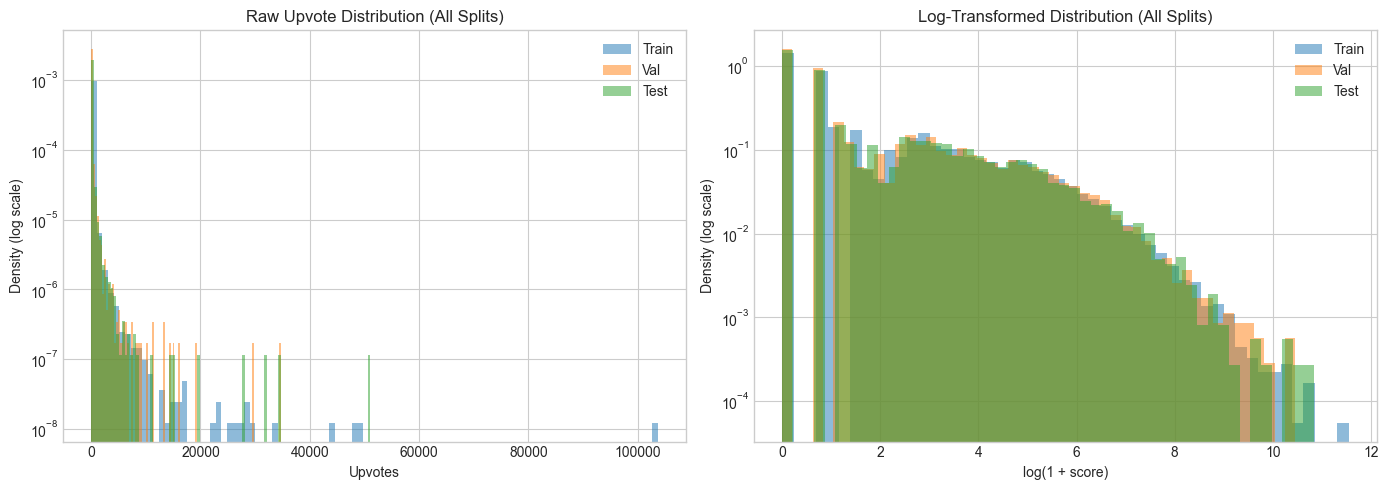

In [8]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df["score"], bins=100, alpha=0.5, label="Train", density=True)
axes[0].hist(val_df["score"],   bins=100, alpha=0.5, label="Val",   density=True)
axes[0].hist(test_df["score"],  bins=100, alpha=0.5, label="Test",  density=True)
axes[0].set_yscale("log")
axes[0].set_title("Raw Upvote Distribution (All Splits)")
axes[0].set_xlabel("Upvotes")
axes[0].set_ylabel("Density (log scale)")
axes[0].legend()

axes[1].hist(train_df["log_score"], bins=50, alpha=0.5, label="Train", density=True)
axes[1].hist(val_df["log_score"],   bins=50, alpha=0.5, label="Val",   density=True)
axes[1].hist(test_df["log_score"],  bins=50, alpha=0.5, label="Test",  density=True)
axes[1].set_yscale("log")
axes[1].set_title("Log-Transformed Distribution (All Splits)")
axes[1].set_xlabel("log(1 + score)")
axes[1].set_ylabel("Density (log scale)")
axes[1].legend()

os.makedirs("figures", exist_ok=True)
plt.tight_layout()
plt.savefig("figures/figure1_split_distribution.png", dpi=300)

<a id="figure1"></a>
<div align="center">
<p><strong>Figure 1:</strong> Distribution of Reddit post upvotes across training, validation, and test splits. The similarity of the distributions demonstrates that the stratified sampling procedure preserves the underlying data distribution across all splits.</p>
</div>

## 3. Related Work

Early work on Reddit popularity prediction focused on traditional machine learning approaches. Segall and Zamoshchin [[1]](https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf) framed the problem as binary classification, using subreddit metadata and bag-of-words title features to predict whether a post would be popular. While effective for coarse-grained prediction, this approach loses information by reducing a continuous engagement signal to a binary label.

Reevesman et al. [[2]](https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc) applied random forest regression to predict Reddit comment karma, demonstrating that ensemble tree methods can capture non-linear interactions between features. However, their work focused on comment-level signals rather than post titles, and did not incorporate deep language understanding.

Kim [[3]](https://arxiv.org/abs/2106.07380) conducted a broader comparison of linear regression, random forests, and neural networks on Reddit post popularity, finding that neural networks performed best when text features were included. This work identified transformer-based models as a natural next step, motivating the use of DistilBERT in this project.

A common limitation across prior work is the reliance on shallow text representations such as TF-IDF or bag-of-words, which treat words independently and ignore contextual meaning. Transformer-based models like BERT (Devlin et al., 2019) [[4]](https://arxiv.org/abs/1810.04805) address this by encoding the full context of each word relative to all others in the sequence, enabling much richer text representations.

## 4. Dataset

The dataset is derived from the Reddit submission corpus available via Academic Torrents (Pushshift). The final dataset contains **450,000 posts** split into training (315,000), validation (67,500), and test (67,500) sets. Each post includes the following:

- **title** — the post title, used as the primary text input to both BERT models
- **content** — the post body text, used as additional input to the content-aware model
- **score** — the raw upvote count
- **log_score** — `log(1 + score)`, the target variable used for all models
- **Metadata features** — 12 structured features available at posting time:

| Feature | Description |
|---|---|
| `has_content` | Whether the post has a body beyond the title |
| `nsfw` | Whether the post is marked as adult content |
| `is_self` | Whether it is a self-post (text) vs. link post |
| `hour` | Hour of day the post was submitted |
| `day_of_week` | Day of week (0=Monday, 6=Sunday) |
| `is_weekend` | Whether the post was submitted on a weekend |
| `title_length` | Number of words in the title |
| `char_length` | Number of characters in the title |
| `uppercase_ratio` | Proportion of uppercase characters |
| `num_exclamations` | Number of exclamation marks |
| `num_questions` | Number of question marks |
| `content_length` | Length of post body in characters |

Of the 315,000 training posts, approximately 47% (149,684) contain body text beyond the title, while the remaining 53% (165,316) are title-only posts — either link posts or posts submitted without body content. The target variable `log_score` is used instead of raw score to address the highly skewed upvote distribution.

## 5. Data Preprocessing

The dataset was already cleaned during the preprocessing pipeline described in Section 0.2. Key steps applied upstream include filtering invalid posts, stratified sampling across four score bins, applying `log_score = log(1 + score)`, and engineering the 12 metadata features. No additional cleaning is required here. The one preprocessing step applied within this notebook is **metadata normalization** for the DistilBERT models, described in Section 8.1.

## 6. Exploratory Data Analysis

The upvote distribution explored in Figure 1 shows that the raw score distribution is extremely right-skewed — the vast majority of posts receive very few upvotes while a small number go viral. After applying the log transformation, the distribution becomes much more symmetric and suitable for regression modeling.

The consistency of distributions across train, validation, and test splits confirms that the stratified sampling strategy successfully preserved the overall distribution in each split. This is important because it means validation and test RMSE scores are representative of real-world performance.

In [9]:
# Content availability breakdown
print("Posts with content:    ", (train_df["content"] != "").sum())
print("Posts without content: ", (train_df["content"] == "").sum())
print("\nhas_content distribution:")
print(train_df["has_content"].value_counts())

Posts with content:     37544
Posts without content:  41129

has_content distribution:
has_content
0    41129
1    37544
Name: count, dtype: int64


## 7. Baseline Models

The goal of this section is to establish baseline performance using traditional machine learning models before introducing the DistilBERT hybrid models. All baseline models use only the 12 structured metadata features — none of them read the post title or body. This isolates the contribution of language understanding and lets us quantify how much value the transformer architecture adds.

All models are evaluated on the **validation set** using RMSE. The test set is held out until the final evaluation in Section 12.

#### 7.1 Feature Setup

The 12 metadata features are extracted from the dataframes and split into train, validation, and test arrays. These same features are later used as the metadata input to both hybrid BERT models.

In [10]:
features = [
    "has_content", "nsfw", "is_self",
    "hour", "day_of_week", "is_weekend",
    "title_length", "char_length",
    "uppercase_ratio", "num_exclamations",
    "num_questions", "content_length"
]

X_train = train_df[features]
y_train = train_df["log_score"]
X_val   = val_df[features]
y_val   = val_df["log_score"]
X_test  = test_df[features]
y_test  = test_df["log_score"]

#### 7.2 Dummy Regressor

The Dummy Regressor predicts the mean `log_score` of the training set for every post, completely ignoring all input features. It sets the floor — any model that cannot beat this is not learning anything useful.

In [11]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_val)
dummy_rmse   = np.sqrt(mean_squared_error(y_val, y_pred_dummy))

print(f"Dummy RMSE: {dummy_rmse:.4f}")

Dummy RMSE: 1.9505


#### 7.3 Ridge Regression

Ridge Regression is a linear model that learns a weighted combination of the 12 metadata features to predict `log_score`. The ridge penalty adds a small cost for large weights, which helps when features are correlated — for example, `title_length` (word count) and `char_length` (character count) carry very similar information.

Feature scaling is applied before training since Ridge is sensitive to the magnitude of input values. The scaler is fit on the training set only and then applied to validation and test sets to prevent data leakage.

In [12]:
ridge_scaler   = StandardScaler()
X_train_scaled = ridge_scaler.fit_transform(X_train)
X_val_scaled   = ridge_scaler.transform(X_val)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_val_scaled)
ridge_rmse   = np.sqrt(mean_squared_error(y_val, y_pred_ridge))

print(f"Ridge RMSE: {ridge_rmse:.4f}")

Ridge RMSE: 1.6909


#### 7.4 Random Forest Regressor

A Random Forest builds many decision trees independently and averages their predictions. Unlike Ridge Regression, it can capture non-linear relationships between features. It also does not require feature scaling since trees split on rank order, not magnitude.

In [13]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_val)
rf_rmse   = np.sqrt(mean_squared_error(y_val, y_pred_rf))

print(f"Random Forest RMSE: {rf_rmse:.4f}")

Random Forest RMSE: 1.5578


#### 7.5 Baseline Comparison

The bar chart below summarizes validation RMSE across all three baseline models. Random Forest outperforms Ridge by a meaningful margin, confirming that non-linear feature interactions contribute to predictive power. However, all three models rely entirely on metadata — none of them read the post title or body. The DistilBERT models in Section 8 incorporate both text and metadata.

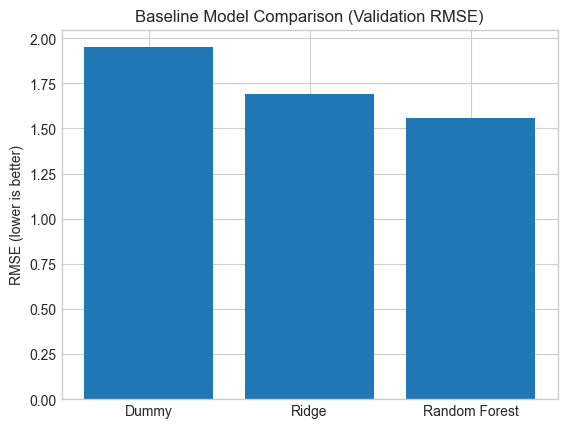

In [14]:
models_baseline      = ["Dummy", "Ridge", "Random Forest"]
rmse_baseline_values = [dummy_rmse, ridge_rmse, rf_rmse]

plt.figure()
plt.bar(models_baseline, rmse_baseline_values)
plt.ylabel("RMSE (lower is better)")
plt.title("Baseline Model Comparison (Validation RMSE)")
plt.savefig("figures/figure2_baseline_comparison.png", dpi=300)
plt.show()

## 8. DistilBERT Hybrid Models

![DistilBERT model overview](https://raw.githubusercontent.com/kyuz0/llm-chronicles/main/5.2%20-%20BERT/BERT-models.png)

**DistilBERT** is a compressed version of BERT (Devlin et al., 2019) [[4]](https://arxiv.org/abs/1810.04805), a transformer-based language model that reads an entire sentence at once and learns how each word relates to every other word in context. Using a technique called knowledge distillation, DistilBERT (Sanh et al., 2019) [[5]](https://arxiv.org/abs/1910.01108) achieves 40% fewer parameters and 60% faster inference while retaining ~97% of BERT's performance — making it well suited for this project where inputs are short (Reddit titles are capped at 300 characters), training data is large (315,000 posts), and compute is limited to a Colab T4 GPU.

We train two variants of the same hybrid architecture:

1. **Title + Metadata model** — encodes only the post title alongside the 12 metadata features
2. **Content-aware model** — encodes the post title concatenated with the body text (when available) alongside the same metadata features

This controlled comparison directly answers the project's central question: does incorporating post body text beyond the title improve popularity prediction?

#### 8.1 Metadata Normalization

Before feeding data into either hybrid model, we address a subtle but important issue. DistilBERT produces a `[CLS]` embedding where all values sit roughly between −1 and 1. Our metadata features, however, operate on completely different scales — `content_length` can be in the thousands, while `uppercase_ratio` is always between 0 and 1. When these are concatenated and passed into the regression head, the model naturally pays more attention to the larger numbers simply because they are bigger, not because they are more informative. The text signal from DistilBERT ends up being drowned out.

This is the same reason we applied `StandardScaler` to Ridge Regression in Section 7.3. We scale all metadata features to mean 0 and standard deviation 1 so that both the text embeddings and the metadata enter the regression head on equal footing.

We also save a copy of the original unscaled validation set (`val_df_raw`) so we can use real post metadata in the prediction demo later without double-scaling.

In [15]:
# Save unscaled copies before transforming — used later in prediction demo
val_df_raw  = val_df.copy()
test_df_raw = test_df.copy()

scaler   = StandardScaler()
train_df = train_df.copy()
val_df   = val_df.copy()
train_df[features] = scaler.fit_transform(train_df[features])
val_df[features]   = scaler.transform(val_df[features])

#### 8.2 Tokenizer

We load DistilBERT's WordPiece tokenizer, which splits text into subword units and maps them to integer token IDs. The same tokenizer was used during DistilBERT's pretraining, so it must be used here too for the embeddings to be meaningful.

In [16]:
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")

#### 8.3 Datasets

We define two custom PyTorch Dataset classes — one for each model variant. Both use lazy tokenization to avoid storing ~315k × 80 token sequences in RAM simultaneously, which would exhaust memory on a Colab T4 session.

**`HybridDataset`** (title + metadata) — tokenizes the post title only.

**`HybridDatasetFull`** (title + content + metadata) — concatenates the title and body text using a `[SEP]` separator when body text is available, and falls back to title only when no body exists. `max_length` is increased to 128 to accommodate the additional content tokens.

In [17]:
class HybridDataset(Dataset):
    """
    Title + metadata model dataset.
    Tokenizes post titles lazily (one at a time) to avoid OOM on Colab.
    """

    def __init__(self, df):
        self.texts  = df["title"].astype(str).tolist()
        self.meta   = df[features].values.astype(np.float32)
        self.labels = df["log_score"].values.astype(np.float32)

    def __getitem__(self, idx):
        enc = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=80,        # Reddit titles capped at 300 chars (~80 tokens)
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["metadata"] = torch.tensor(self.meta[idx])
        item["labels"]   = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


def build_input(title, content):
    """Concatenate title and content with [SEP] separator when content exists."""
    title   = str(title)
    content = str(content) if pd.notna(content) else ""
    content = content.strip()
    if content and content not in {"[deleted]", "[removed]"}:
        return title + " [SEP] " + content
    return title


class HybridDatasetFull(Dataset):
    """
    Content-aware dataset — combines post title and body text as input.
    Falls back to title only when post has no body content.
    max_length=128 to accommodate title + content tokens.
    """

    def __init__(self, df):
        self.texts  = [build_input(row["title"], row["content"])
                       for _, row in df.iterrows()]
        self.meta   = df[features].values.astype(np.float32)
        self.labels = df["log_score"].values.astype(np.float32)

    def __getitem__(self, idx):
        enc = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=128,       # longer to accommodate body text
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["metadata"] = torch.tensor(self.meta[idx])
        item["labels"]   = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

#### 8.4 Model Architecture

Both model variants share the same `HybridModel` architecture. The only difference between them is the input text passed to the tokenizer — the architecture itself is identical.

The model combines two sources of information:

1. **Text** — DistilBERT encodes the input text and produces a 768-dimensional `[CLS]` vector. The `[CLS]` token is placed at the start of every input sequence. By the time it passes through all 6 transformer layers, it has aggregated contextual information from every other token in the input.

2. **Metadata** — the 12 normalized metadata features are concatenated directly onto the CLS vector, giving a 780-dimensional combined representation.

This combined vector is passed through a regression head that compresses it down to a single predicted `log_score`. BatchNorm stabilizes training, ReLU adds non-linearity, and Dropout (0.3) reduces overfitting.

In [18]:
class HybridModel(nn.Module):
    """
    Hybrid regression model combining DistilBERT text embeddings with
    structured metadata features to predict Reddit post popularity (log_score).

    Used for both the title-only and content-aware variants — the only
    difference between the two is the input text passed to the tokenizer.
    """

    def __init__(self, num_meta_features):
        """
        Args:
            num_meta_features (int): Number of metadata features to concatenate
                                     with the CLS embedding (e.g. 12).
        """
        super().__init__()
        self.bert    = DistilBertModel.from_pretrained("distilbert-base-uncased")
        self.loss_fn = nn.MSELoss()   # instantiated once, not per forward pass
        self.regressor = nn.Sequential(
            nn.Linear(768 + num_meta_features, 256),  # 768 (CLS) + metadata
            nn.BatchNorm1d(256),                       # stabilize mixed-scale inputs
            nn.ReLU(),
            nn.Dropout(0.3),                           # regularization
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 1)                           # single scalar output
        )

    def forward(self, input_ids, attention_mask, metadata, labels=None):
        """
        Forward pass through the model.

        Args:
            input_ids (Tensor):      Tokenized input IDs, shape (batch, seq_len).
            attention_mask (Tensor): Padding mask, shape (batch, seq_len).
            metadata (Tensor):       Normalized metadata, shape (batch, num_meta_features).
            labels (Tensor):         Ground truth log_scores, shape (batch,). Optional —
                                     if provided, MSE loss is computed and returned.

        Returns:
            dict with keys:
                'loss':   MSELoss scalar if labels provided, else None.
                'logits': Predicted log_scores, shape (batch,).
        """
        cls    = self.bert(input_ids=input_ids,
                           attention_mask=attention_mask).last_hidden_state[:, 0]
        logits = self.regressor(torch.cat([cls, metadata], dim=1)).squeeze(-1)
        loss   = self.loss_fn(logits, labels) if labels is not None else None
        return {"loss": loss, "logits": logits}

#### 8.5 Training Configuration

Both models use identical training configuration via HuggingFace's `Trainer` API. Key decisions:

- `learning_rate=2e-5` — standard fine-tuning rate for transformer models
- `warmup_steps=500` — gradually ramps the learning rate from 0 to avoid destabilizing pretrained weights early in training
- `weight_decay=0.01` — L2 regularization to reduce overfitting
- `fp16=True` — halves VRAM usage and speeds up training on the T4 GPU
- `num_train_epochs=2` — chosen after an initial 3-epoch run showed mild overfitting at epoch 3

In [19]:
def compute_metrics(eval_pred):
    preds, labels = eval_pred
    return {"rmse": np.sqrt(mean_squared_error(labels, preds.flatten()))}

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=64,
    num_train_epochs=2,
    eval_strategy="epoch",
    logging_steps=200,
    weight_decay=0.01,
    warmup_steps=500,
    fp16=True,
)

#### 8.6 Model 1 — Title + Metadata

The first model encodes only the post title alongside the 12 metadata features. This serves as the title-only baseline for our BERT comparison.

In [20]:
train_dataset = HybridDataset(train_df)
val_dataset   = HybridDataset(val_df)
model         = HybridModel(num_meta_features=len(features))

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 8244.66it/s]
DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

#### 8.7 Evaluate — Title + Metadata Model

In [ ]:
preds  = trainer.predict(val_dataset)
y_true = val_df["log_score"].values
y_pred = preds.predictions.flatten()

bert_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
bert_mae  = mean_absolute_error(y_true, y_pred)

print(f"Title + Metadata BERT RMSE: {bert_rmse:.4f}")
print(f"Title + Metadata BERT MAE:  {bert_mae:.4f}")

#### 8.8 Model 2 — Content-Aware (Title + Content + Metadata)

The second model encodes the post title concatenated with the body text (when available), alongside the same 12 metadata features. For posts with no body, the input is identical to Model 1. The comparison between the two models therefore isolates the marginal contribution of post body text for the ~47% of posts that contain it.

In [ ]:
train_dataset_full = HybridDatasetFull(train_df)
val_dataset_full   = HybridDatasetFull(val_df)
model_full         = HybridModel(num_meta_features=len(features))

trainer_full = Trainer(
    model=model_full,
    args=training_args,
    train_dataset=train_dataset_full,
    eval_dataset=val_dataset_full,
    compute_metrics=compute_metrics,
)

trainer_full.train()

#### 8.9 Evaluate — Content-Aware Model

In [ ]:
preds_full  = trainer_full.predict(val_dataset_full)
y_pred_full = preds_full.predictions.flatten()

full_rmse = np.sqrt(mean_squared_error(y_true, y_pred_full))
full_mae  = mean_absolute_error(y_true, y_pred_full)

print(f"Content-aware BERT RMSE: {full_rmse:.4f}")
print(f"Content-aware BERT MAE:  {full_mae:.4f}")

## 9. Results

The table below summarizes validation RMSE across all models. Both BERT variants outperform all baselines, and the content-aware model is compared against the title-only model to assess the value of post body text.

| Model | Validation RMSE |
|---|---|
| Dummy Regressor | — |
| Ridge Regression | — |
| Random Forest | — |
| BERT (title + metadata) | — |
| BERT (content-aware) | — |

*Fill in RMSE values after running all cells.*

In [ ]:
models_all      = ["Dummy", "Ridge", "Random Forest",
                   "BERT\n(title+meta)", "BERT\n(content-aware)"]
rmse_values_all = [dummy_rmse, ridge_rmse, rf_rmse, bert_rmse, full_rmse]

plt.figure(figsize=(10, 5))
colors = ["#888780", "#888780", "#888780", "#1D9E75", "#0F6E56"]
plt.bar(models_all, rmse_values_all, color=colors)
plt.ylabel("RMSE (lower is better)")
plt.title("Model Comparison — Validation RMSE")
plt.tight_layout()
plt.savefig("figures/figure3_all_model_comparison.png", dpi=300)
plt.show()

print(f"\nDummy         RMSE: {dummy_rmse:.4f}")
print(f"Ridge         RMSE: {ridge_rmse:.4f}")
print(f"Random Forest RMSE: {rf_rmse:.4f}")
print(f"BERT (title)  RMSE: {bert_rmse:.4f}")
print(f"BERT (full)   RMSE: {full_rmse:.4f}")
print(f"\nContent-aware improvement: {bert_rmse - full_rmse:.4f} RMSE")

#### 9.1 Predicted vs Actual

Scatter plots of predicted vs actual `log_score` for both BERT models. A perfect model would follow the red diagonal exactly. Both models perform well in the low-to-mid range but underestimate high-engagement posts.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds_arr, title in [
    (axes[0], y_pred,      "Title + Metadata"),
    (axes[1], y_pred_full, "Content-Aware")
]:
    ax.scatter(y_true, preds_arr, alpha=0.1, s=5)
    ax.plot([min(y_true), max(y_true)],
            [min(y_true), max(y_true)], "r--", linewidth=1)
    ax.set_xlabel("Actual log_score")
    ax.set_ylabel("Predicted log_score")
    ax.set_title(f"Predicted vs Actual — {title}")

plt.tight_layout()
plt.savefig("figures/figure4_pred_vs_actual.png", dpi=300)
plt.show()

#### 9.2 Error Distribution

Error distributions for both models. A mean error close to zero indicates the model is well-calibrated overall. The long left tail represents viral posts that the model underestimates.

In [ ]:
errors_title   = y_pred      - y_true
errors_content = y_pred_full - y_true

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, errors, title in [
    (axes[0], errors_title,   "Title + Metadata"),
    (axes[1], errors_content, "Content-Aware")
]:
    ax.hist(errors, bins=80, density=True)
    ax.axvline(0, color="r", linestyle="--", linewidth=1)
    ax.set_xlabel("Prediction Error (predicted − actual)")
    ax.set_ylabel("Density")
    ax.set_title(f"Error Distribution — {title}")

plt.tight_layout()
plt.savefig("figures/figure5_error_dist.png", dpi=300)
plt.show()

print(f"Title model   — Mean error: {errors_title.mean():.4f} | Std: {errors_title.std():.4f}")
print(f"Content model — Mean error: {errors_content.mean():.4f} | Std: {errors_content.std():.4f}")

## 10. Discussion

Both hybrid DistilBERT models outperformed all baseline models, demonstrating that post titles carry meaningful signal for predicting upvote counts beyond what structured metadata alone can capture. The gap between Random Forest and the title-only BERT model is particularly informative — Random Forest already exploits non-linear interactions between metadata features, yet BERT still improves upon it by reading the actual text of the title.

**Title-only vs content-aware comparison.** Of the 315,000 training posts, approximately 47% contain body text. For posts without body content, both models receive identical input, meaning the comparison isolates the marginal contribution of post body text for the subset of posts that contain it. The difference in RMSE between the two models quantifies how much additional signal the body text provides beyond the title.

Notably, the hybrid models achieve these results without access to subreddit identity — one of the strongest predictors of post popularity. Rather than encoding community-specific behavior directly, the model must infer engagement potential from the title text and general metadata alone. This makes the approach more generalizable across communities. Adding subreddit frequency encoding as a feature would be a natural extension.

**Most impactful design decisions.** Metadata normalization was critical — without it, the regression head would disproportionately weight raw metadata values over the CLS embedding, effectively ignoring the text signal. Lazy tokenization was necessary to avoid out-of-memory errors on the Colab T4 session.

**Overfitting.** Mild overfitting was observed during a 3-epoch training run — validation loss improved from epoch 1 to epoch 2 but increased at epoch 3. Training for 2 epochs with Dropout (0.3) and weight decay (0.01) provided the best generalization.

**Limitations.** Both models show strong calibration in the low-to-mid engagement range but consistently underestimate viral posts by 5–8 log units. This is expected — the training data contains very few posts at extreme popularity levels even after stratified sampling. The model is also limited to features available at posting time and cannot use user history or future engagement signals.

## 11. Conclusion & Future Work

This project compared five models for predicting Reddit post popularity: a Dummy Regressor, Ridge Regression, Random Forest, a hybrid DistilBERT title+metadata model, and a content-aware hybrid DistilBERT model. Both BERT variants outperformed all baselines, confirming that language understanding adds value beyond structured metadata.

Key findings:
- Metadata features alone provide a reasonable baseline but incorporating title text improves performance
- Metadata normalization is critical when combining BERT embeddings with structured features
- Mild overfitting appears at 3 epochs; 2 epochs with dropout and weight decay provides the best generalization
- The comparison between the title-only and content-aware models quantifies the marginal value of post body text for the ~47% of posts that contain it

**Future work** could explore adding subreddit frequency encoding as a feature, fine-tuning on subreddit-specific data, or experimenting with larger transformer models such as RoBERTa. A longer maximum sequence length for the content-aware model could also better capture long-form posts.

## 12. Final Evaluation on Test Set

The test set is evaluated exactly once, after all model development and hyperparameter decisions have been finalized. All models are evaluated here using the same held-out test split.

In [ ]:
# Normalize test metadata using the same scaler fit on train
test_df_eval           = test_df_raw.copy()
test_df_eval[features] = scaler.transform(test_df_eval[features])
X_test_scaled          = ridge_scaler.transform(X_test)

# Dummy
dummy_test_rmse = np.sqrt(mean_squared_error(y_test, dummy.predict(X_test)))

# Ridge
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))

# Random Forest
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf.predict(X_test)))

# BERT title model
test_dataset  = HybridDataset(test_df_eval)
test_preds    = trainer.predict(test_dataset)
bert_test_rmse = np.sqrt(mean_squared_error(
    test_df_eval["log_score"].values,
    test_preds.predictions.flatten()
))

# BERT content-aware model
test_dataset_full  = HybridDatasetFull(test_df_eval)
test_preds_full    = trainer_full.predict(test_dataset_full)
full_test_rmse = np.sqrt(mean_squared_error(
    test_df_eval["log_score"].values,
    test_preds_full.predictions.flatten()
))

print("Final Test Set Results")
print("=" * 40)
print(f"Dummy Regressor        RMSE: {dummy_test_rmse:.4f}")
print(f"Ridge Regression       RMSE: {ridge_test_rmse:.4f}")
print(f"Random Forest          RMSE: {rf_test_rmse:.4f}")
print(f"BERT (title+meta)      RMSE: {bert_test_rmse:.4f}")
print(f"BERT (content-aware)   RMSE: {full_test_rmse:.4f}")

## 13. Prediction Demo

To illustrate what the models have learned, we demonstrate inference on individual posts. We use `val_df_raw` — the unscaled copy of the validation set saved before normalization — to ensure metadata values are not double-scaled when passed through the prediction function.

Note: DistilBERT is an encoder-only model and cannot generate text. It can only predict a score for a given input title.

In [ ]:
def predict_score(title, metadata_values, content="", use_content_model=False):
    """
    Predict the log_score for a Reddit post title.

    Args:
        title (str):            The post title.
        metadata_values (dict): Raw (unscaled) values for all metadata features.
        content (str):          Optional post body text (used when use_content_model=True).
        use_content_model (bool): If True, uses the content-aware model.

    Returns:
        float: Predicted log_score.
    """
    m      = model_full if use_content_model else model
    device = next(m.parameters()).device
    m.eval()

    text = build_input(title, content) if use_content_model else title
    mlen = 128 if use_content_model else 80

    enc = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=mlen,
        return_tensors="pt"
    )

    meta_df     = pd.DataFrame([metadata_values])[features]
    meta_scaled = scaler.transform(meta_df)
    meta_tensor = torch.tensor(meta_scaled, dtype=torch.float32)

    input_ids      = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    meta_tensor    = meta_tensor.to(device)

    with torch.inference_mode():
        output = m(input_ids=input_ids,
                   attention_mask=attention_mask,
                   metadata=meta_tensor)

    log_score = output["logits"].item()
    upvotes   = int(np.expm1(log_score))
    return log_score, upvotes

#### 13.1 Top 5 Viral Posts

We plug the top 5 highest-scoring posts from the validation set back into both models using their real metadata. Both models consistently underestimate viral posts — predicting log scores of 3–5 for posts with actual scores above 11. This is expected: the training data contains very few posts at this popularity level, so the model has not learned to predict extreme engagement. This is also visible in the scatter plots in Section 9.1, where predictions flatten out well below the diagonal for high actual scores.

In [ ]:
top_5 = val_df_raw.nlargest(5, "log_score")

for _, post in top_5.iterrows():
    meta = {k: post[k] for k in features}
    p1, u1 = predict_score(post["title"], meta, use_content_model=False)
    p2, u2 = predict_score(post["title"], meta,
                            content=post["content"], use_content_model=True)

    print(f"Title:          {post['title'][:80]}")
    print(f"Actual:         {post['log_score']:.4f} (~{int(post['score'])} upvotes)")
    print(f"Title model:    {p1:.4f} (~{u1} upvotes) | Error: {p1 - post['log_score']:.4f}")
    print(f"Content model:  {p2:.4f} (~{u2} upvotes) | Error: {p2 - post['log_score']:.4f}")
    print("-" * 70)

#### 13.2 Average Post

We find the post closest to the mean `log_score` in the validation set and predict its score using both models. The models should perform much better here since the bulk of training data lives in this range.

In [ ]:
mean_log_score = val_df_raw["log_score"].mean()
closest_idx    = (val_df_raw["log_score"] - mean_log_score).abs().idxmin()
mean_post      = val_df_raw.loc[closest_idx]
meta           = {k: mean_post[k] for k in features}

print(f"Mean log_score in validation set: {mean_log_score:.4f}")
print(f"\n=== Closest Post to Mean ===")
print(f"Title:            {mean_post['title']}")
print(f"Actual score:     {int(mean_post['score'])} upvotes")
print(f"Actual log_score: {mean_post['log_score']:.4f}")
print()

p1, u1 = predict_score(mean_post["title"], meta, use_content_model=False)
p2, u2 = predict_score(mean_post["title"], meta,
                        content=mean_post["content"], use_content_model=True)

print(f"Title model   — Predicted: {p1:.4f} (~{u1} upvotes)")
print(f"Content model — Predicted: {p2:.4f} (~{u2} upvotes)")

## 14. References

[1] J. Segall and A. Zamoshchin, "Predicting Reddit Post Popularity," Stanford University CS229 Project Report, 2012.
Available: https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf

[2] A. Reevesman, G. K. Guruswamy, H. Le, M. Alfaro, and P. Agrawal, "Predicting Reddit Comment Upvotes with Machine Learning," *Towards Data Science*, Medium, Jan. 2019.
Available: https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc

[3] J. Kim, "Predicting the Popularity of Reddit Posts with AI," arXiv preprint arXiv:2106.07380, 2021.
Available: https://arxiv.org/abs/2106.07380

[4] J. Devlin, M. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding," arXiv preprint arXiv:1810.04805, 2019.
Available: https://arxiv.org/abs/1810.04805

[5] V. Sanh, L. Debut, J. Chaumond, and T. Wolf, "DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter," arXiv preprint arXiv:1910.01108, 2019.
Available: https://arxiv.org/abs/1910.01108